# Quantizing Qwen2.5-3B-Instruct: memory, speed and quality trade-offs

This notebook loads `Qwen/Qwen2.5-3B-Instruct` in four precisions: FP16 (baseline), INT8 (bitsandbytes LLM.int8), NF4 (4-bit) and NF4 with double quantization. Each one is compared on:

* weight memory and peak VRAM while decoding
* decode throughput (batch size 1) and prefill throughput at several prompt lengths
* quality: WikiText-2 perplexity and accuracy on a 300-question MMLU subset
* the longest context that runs on the GPU without going out of memory, plus an analytic estimate of the same for 4-24 GB cards

Everything was run on a free Colab T4.

## 1. Setup

In [1]:
!pip -q install -U transformers accelerate bitsandbytes datasets matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import os
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN, add_to_git_credential=False)

In [3]:
import os, gc, json, time, math, random, platform
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig, BitsAndBytesConfig

assert torch.cuda.is_available(), "No GPU available"
DEVICE = "cuda"
props = torch.cuda.get_device_properties(0)
GPU_NAME, GPU_TOTAL_GB = props.name, props.total_memory / 1024**3
OUT_DIR = "/content/qwen_quant_out"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"GPU: {GPU_NAME} | {GPU_TOTAL_GB:.1f} GB | torch {torch.__version__} | transformers {transformers.__version__} | python {platform.python_version()}")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def gb(x): return x / 1024**3
def sync(): torch.cuda.synchronize()
def cleanup():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.ipc_collect()

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


GPU: Tesla T4 | 14.6 GB | torch 2.11.0+cu130 | transformers 5.22.1 | python 3.13.16


## 2. Configuration
Model, precisions to compare and evaluation sizes. The first entry in `CONFIGS` is the baseline all deltas are computed against.

In [4]:
SEED = 42
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"   

# Precisions to compare. The first entry is the baseline.
CONFIGS = [
    dict(name="FP16 (baseline)",        kind="fp16"),
    dict(name="INT8 (bnb LLM.int8)",    kind="int8"),
    dict(name="NF4 (bnb 4-bit)",        kind="nf4"),
    dict(name="NF4 + double-quant",     kind="nf4dq"),
]

# Pre-quantized checkpoints (AWQ / GPTQ) need extra packages; not run here.
RUN_PREQUANT = False
PREQUANT_CONFIGS = [
    dict(name="AWQ INT4 (pre-quantized)", kind="prequant", repo="Qwen/Qwen2.5-3B-Instruct-AWQ"),
]
if RUN_PREQUANT:
    CONFIGS += PREQUANT_CONFIGS

# ---- quality evaluation ----
PPL_MAX_LEN = 1024        # window length for perplexity
PPL_MAX_WINDOWS = 100     # 100 x 1024 = ~100k tokens of WikiText-2 test. None = whole test set (slower)
MMLU_N = 300              # random MMLU test questions (0-shot, answer-letter logits)

# ---- speed / memory evaluation ----
PREFILL_CTXS = [512, 1024, 2048, 4096]       # prompt lengths for prefill throughput
DECODE_PROMPT_LEN = 512
DECODE_NEW_TOKENS = 128
REPEATS = 3                                  # median over repeats
PROBE_CTXS = [1024, 2048, 4096, 8192, 16384] # context lengths to test for "does it fit?" (stops at first OOM)

## 3. Data
* **Perplexity:** WikiText‑2 test split (standard LM benchmark), non-overlapping windows.
* **Accuracy proxy:** a random subset of MMLU (57 subjects), zero-shot, scored by comparing the logits of the tokens ` A/B/C/D`.
  This is a *relative* degradation measure (FP16 vs. quantized) — absolute scores will differ from published 5-shot numbers.

In [5]:
from datasets import load_dataset
seed_all(SEED)
tok = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN)
if tok.pad_token_id is None:
    tok.pad_token = tok.eos_token

wt = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
test_text = "\n\n".join(wt["text"])
ppl_ids = tok(test_text, return_tensors="pt").input_ids
print("WikiText-2 test tokens:", ppl_ids.shape[1])

mmlu = load_dataset("cais/mmlu", "all", split="test").shuffle(seed=SEED).select(range(MMLU_N))
print("MMLU subset:", len(mmlu), "questions,", len(set(mmlu["subject"])), "subjects")

LETTERS = ["A", "B", "C", "D"]
letter_ids = [tok.encode(" " + l, add_special_tokens=False)[-1] for l in LETTERS]

def fmt_mmlu(ex):
    subj = ex["subject"].replace("_", " ")
    p = f"The following is a multiple choice question about {subj}.\n\n{ex['question']}\n"
    for l, c in zip(LETTERS, ex["choices"]):
        p += f"{l}. {c}\n"
    return p + "Answer:"

# Fixed token stream used to build benchmark prompts of any length
bench_stream = ppl_ids[0]
def bench_ids(n):
    assert n <= bench_stream.numel(), "Requested context longer than the benchmark text."
    return bench_stream[:n].unsqueeze(0).to(DEVICE)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

... (22 outputs left out)

Generating validation split:   0%|          | 0/1531 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/285 [00:00<?, ? examples/s]

Generating auxiliary_train split:   0%|          | 0/99842 [00:00<?, ? examples/s]

MMLU subset: 300 questions, 56 subjects


## 4. Helper functions (loading, quality, speed, memory)

In [6]:
def make_quant_config(kind):
    if kind in ("fp16", "prequant"):
        return None
    if kind == "int8":
        return BitsAndBytesConfig(load_in_8bit=True)
    if kind in ("nf4", "nf4dq"):
        return BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=(kind == "nf4dq"),
        )
    raise ValueError(kind)

def load_model(kind, repo=None):
    cleanup(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    model = AutoModelForCausalLM.from_pretrained(
        repo or MODEL_ID, torch_dtype=torch.float16,
        quantization_config=make_quant_config(kind),
        device_map={"": 0}, token=HF_TOKEN,
    )
    model.eval(); sync()
    return model, time.time() - t0

@torch.no_grad()
def eval_ppl(model, ids, max_len=PPL_MAX_LEN, max_windows=PPL_MAX_WINDOWS):
    n = ids.size(1) // max_len
    if max_windows: n = min(n, max_windows)
    nll, cnt = 0.0, 0
    for i in range(n):
        x = ids[:, i*max_len:(i+1)*max_len].to(DEVICE)
        out = model(x, labels=x)
        nll += out.loss.float().item() * (x.size(1) - 1)
        cnt += x.size(1) - 1
    return math.exp(nll / cnt)

@torch.no_grad()
def eval_mmlu(model):
    correct = 0
    for ex in mmlu:
        ids = tok(fmt_mmlu(ex), return_tensors="pt", truncation=True, max_length=2048).input_ids.to(DEVICE)
        logits = model(ids).logits[0, -1]
        pred = int(torch.argmax(logits[letter_ids]))
        correct += int(pred == ex["answer"])
    return correct / len(mmlu)

@torch.no_grad()
def timed_generate(model, ids, new_tokens):
    sync(); t = time.perf_counter()
    model.generate(
        input_ids=ids, attention_mask=torch.ones_like(ids),
        max_new_tokens=new_tokens, min_new_tokens=new_tokens, do_sample=False,
        temperature=None, top_p=None, top_k=None,
        pad_token_id=tok.pad_token_id, use_cache=True,
    )
    sync(); return time.perf_counter() - t

def bench_prefill(model, ctx, reps=REPEATS):
    ids = bench_ids(ctx)
    timed_generate(model, ids, 1)                       # warm-up
    ts = [timed_generate(model, ids, 1) for _ in range(reps)]
    return ctx / float(np.median(ts))                   # prompt tokens per second

def bench_decode(model, prompt_len=DECODE_PROMPT_LEN, new=DECODE_NEW_TOKENS, reps=REPEATS):
    ids = bench_ids(prompt_len)
    timed_generate(model, ids, 8)                       # warm-up
    vals = []
    for _ in range(reps):
        t1 = timed_generate(model, ids, 1)              # prefill + first token
        tn = timed_generate(model, ids, new)            # prefill + N tokens
        vals.append((new - 1) / max(tn - t1, 1e-9))
    return float(np.median(vals))                       # generated tokens per second (batch 1)

def probe_contexts(model, ctxs):
    # Largest prompt length that completes a forward pass without OOM on THIS gpu
    out, failed = {}, False
    for c in ctxs:
        if failed:
            out[c] = dict(ok=False, peak_gb=None); continue
        cleanup(); torch.cuda.reset_peak_memory_stats()
        ok = True
        try:
            timed_generate(model, bench_ids(c), 1)
            peak = gb(torch.cuda.max_memory_allocated())
        except torch.cuda.OutOfMemoryError:
            ok, peak, failed = False, None, True
        cleanup()
        out[c] = dict(ok=ok, peak_gb=peak)
        print(f"   ctx={c:>6}: {'OK  peak %.2f GB' % peak if ok else 'OOM'}")
    return out

## 5. Run the benchmark
For every configuration the model is loaded, evaluated, then freed. Results are saved to JSON after each configuration so a Colab disconnect does not lose everything.

* **`weights_gb`** – memory footprint of the loaded weights (the "model size" claim).
* **`peak_vram_decode_gb`** – peak allocated VRAM while generating at 512-token context (the "peak VRAM" claim).
* **`max_ctx_ok`** – largest context that really ran on this GPU without OOM.

In [7]:
results = []
cfg_info = AutoConfig.from_pretrained(MODEL_ID, token=HF_TOKEN)   # kept for the analytic fit table later

for cfg in CONFIGS:
    print("\n" + "=" * 78 + f"\n{cfg['name']}\n" + "=" * 78)
    try:
        seed_all(SEED)
        model, load_s = load_model(cfg["kind"], cfg.get("repo"))
        rec = dict(config=cfg["name"], kind=cfg["kind"], load_time_s=round(load_s, 1))
        rec["weights_gb"] = model.get_memory_footprint() / 1024**3
        rec["vram_after_load_gb"] = gb(torch.cuda.memory_allocated())
        print(f"   weights {rec['weights_gb']:.2f} GB | load {load_s:.0f}s")

        print("   perplexity ..."); rec["ppl"] = eval_ppl(model, ppl_ids)
        print("   MMLU ...");       rec["mmlu_acc"] = eval_mmlu(model)
        print(f"   PPL {rec['ppl']:.3f} | MMLU-subset acc {rec['mmlu_acc']*100:.1f}%")

        print("   prefill throughput ...")
        rec["prefill_tps"] = {c: bench_prefill(model, c) for c in PREFILL_CTXS}

        print("   decode throughput ...")
        cleanup(); torch.cuda.reset_peak_memory_stats()
        rec["decode_tps"] = bench_decode(model)
        rec["peak_vram_decode_gb"] = gb(torch.cuda.max_memory_allocated())
        rec["peak_reserved_decode_gb"] = gb(torch.cuda.max_memory_reserved())
        print(f"   decode {rec['decode_tps']:.1f} tok/s | peak {rec['peak_vram_decode_gb']:.2f} GB")

        print("   context-length probe ...")
        probe = probe_contexts(model, PROBE_CTXS)
        rec["probe"] = {str(k): v for k, v in probe.items()}
        oks = [c for c, v in probe.items() if v["ok"]]
        rec["max_ctx_ok"] = max(oks) if oks else 0

        results.append(rec)
        json.dump(results, open(f"{OUT_DIR}/results.json", "w"), indent=2)
    except Exception as e:
        print("   FAILED:", type(e).__name__, str(e)[:300])
        results.append(dict(config=cfg["name"], kind=cfg["kind"], error=f"{type(e).__name__}: {str(e)[:300]}"))
    finally:
        for v in ("model",):
            if v in globals(): del globals()[v]
        cleanup()


FP16 (baseline)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

   weights 1.87 GB | load 17s
   perplexity ...
   MMLU ...
   PPL 10.108 | MMLU-subset acc 68.0%
   prefill throughput ...
   decode throughput ...
   decode 13.9 tok/s | peak 2.14 GB
   context-length probe ...
   ctx=  1024: OK  peak 2.28 GB
   ctx=  2048: OK  peak 2.80 GB
   ctx=  4096: OK  peak 4.71 GB
   ctx=  8192: OK  peak 11.98 GB
   ctx= 16384: OOM

NF4 + double-quant


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

   weights 1.87 GB | load 16s
   perplexity ...
   MMLU ...
   PPL 10.113 | MMLU-subset acc 67.0%
   prefill throughput ...
   decode throughput ...
   decode 13.7 tok/s | peak 2.02 GB
   context-length probe ...
   ctx=  1024: OK  peak 2.16 GB
   ctx=  2048: OK  peak 2.68 GB
   ctx=  4096: OK  peak 4.58 GB
   ctx=  8192: OK  peak 11.86 GB
   ctx= 16384: OOM


## 6. Results table with deltas vs. the baseline

In [8]:
ok = [r for r in results if "error" not in r]
failed = [r for r in results if "error" in r]
if failed: print("Failed configs:", [(f["config"], f["error"]) for f in failed])

rows = []
for r in ok:
    row = {k: v for k, v in r.items() if k not in ("prefill_tps", "probe", "kind")}
    for c, v in r["prefill_tps"].items():
        row[f"prefill_tps@{c}"] = v
    rows.append(row)
df = pd.DataFrame(rows)

b = df.iloc[0]
df["compression_x"]          = b.weights_gb / df.weights_gb
df["vram_reduction_%"]       = (1 - df.peak_vram_decode_gb / b.peak_vram_decode_gb) * 100
df["decode_speedup_x"]       = df.decode_tps / b.decode_tps
df["prefill_speedup_x@2048"] = df["prefill_tps@2048"] / b["prefill_tps@2048"]
df["dPPL"]                   = df.ppl - b.ppl
df["dPPL_%"]                 = (df.ppl / b.ppl - 1) * 100
df["dMMLU_pts"]              = (df.mmlu_acc - b.mmlu_acc) * 100

df.to_csv(f"{OUT_DIR}/results_table.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
show = ["config", "weights_gb", "compression_x", "peak_vram_decode_gb", "vram_reduction_%",
        "decode_tps", "decode_speedup_x", "prefill_tps@2048", "ppl", "dPPL", "dPPL_%",
        "mmlu_acc", "dMMLU_pts", "max_ctx_ok"]
print(f"GPU: {GPU_NAME} ({GPU_TOTAL_GB:.1f} GB) | model: {MODEL_ID}")
df[show].round(3)

GPU: Tesla T4 (14.6 GB) | model: Qwen/Qwen2.5-3B-Instruct


,config,weights_gb,compression_x,peak_vram_decode_gb,vram_reduction_%,decode_tps,decode_speedup_x,prefill_tps@2048,ppl,dPPL,dPPL_%,mmlu_acc,dMMLU_pts,max_ctx_ok
0,FP16 (baseline),5.748,1.000,5.836,0.000,18.654,1.000,1438.218,9.509,0.000,0.000,0.683,0.000,4096
1,INT8 (bnb LLM.int8),3.164,1.817,3.351,42.578,4.821,0.258,1314.264,9.617,0.108,1.135,0.647,-3.667,8192
2,NF4 (bnb 4-bit),1.872,3.070,2.145,63.247,13.934,0.747,1195.429,10.108,0.599,6.294,0.680,-0.333,8192
3,NF4 + double-quant,1.872,3.070,2.024,65.316,13.724,0.736,1200.800,10.113,0.604,6.348,0.670,-1.333,8192


## 7. Plots

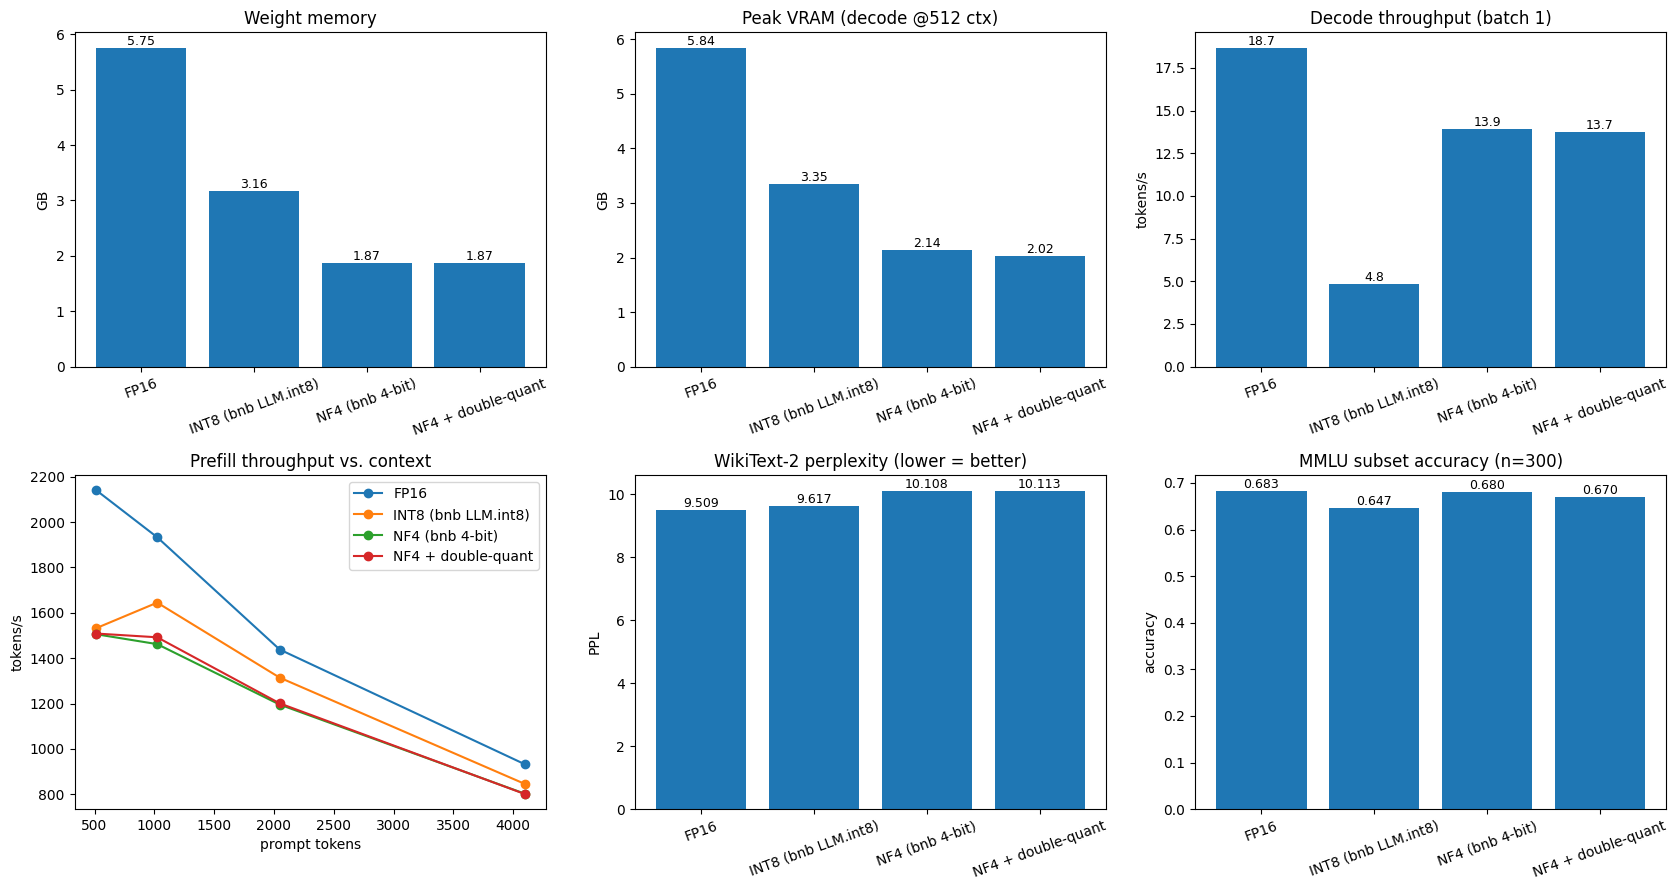

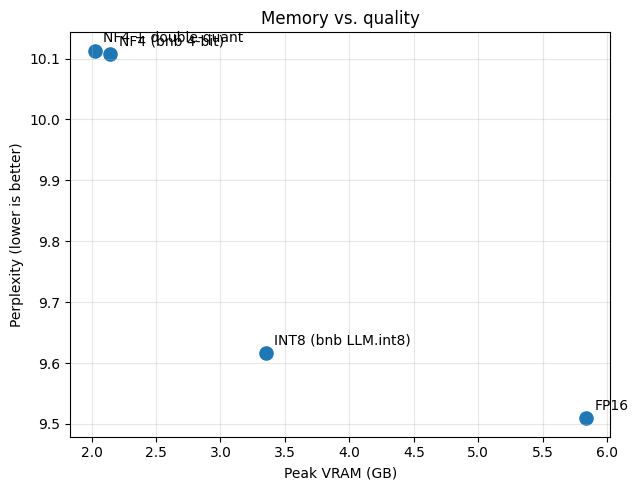

In [9]:
short = [c.split(" (")[0] if "baseline" in c else c for c in df.config]
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
def bar(a, y, title, ylabel, fmt="%.2f"):
    bars = a.bar(short, df[y]); a.set_title(title); a.set_ylabel(ylabel)
    a.tick_params(axis="x", rotation=20)
    for bb, v in zip(bars, df[y]): a.text(bb.get_x()+bb.get_width()/2, v, fmt % v, ha="center", va="bottom", fontsize=9)
bar(ax[0,0], "weights_gb", "Weight memory", "GB")
bar(ax[0,1], "peak_vram_decode_gb", "Peak VRAM (decode @512 ctx)", "GB")
bar(ax[0,2], "decode_tps", "Decode throughput (batch 1)", "tokens/s", "%.1f")
for i, r in df.iterrows():
    ax[1,0].plot(PREFILL_CTXS, [r[f"prefill_tps@{c}"] for c in PREFILL_CTXS], marker="o", label=short[i])
ax[1,0].set_title("Prefill throughput vs. context"); ax[1,0].set_xlabel("prompt tokens"); ax[1,0].set_ylabel("tokens/s"); ax[1,0].legend()
bar(ax[1,1], "ppl", "WikiText-2 perplexity (lower = better)", "PPL", "%.3f")
bar(ax[1,2], "mmlu_acc", f"MMLU subset accuracy (n={MMLU_N})", "accuracy", "%.3f")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/summary_plots.png", dpi=160); plt.show()

# Memory / quality Pareto view
plt.figure(figsize=(6.5, 5))
plt.scatter(df.peak_vram_decode_gb, df.ppl, s=90)
for i, r in df.iterrows(): plt.annotate(short[i], (r.peak_vram_decode_gb, r.ppl), textcoords="offset points", xytext=(6, 6))
plt.xlabel("Peak VRAM (GB)"); plt.ylabel("Perplexity (lower is better)"); plt.title("Memory vs. quality")
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pareto_vram_vs_ppl.png", dpi=160); plt.show()

## 8. "Does it fit my target GPU, and at what context length?"
Measured OOM probes above only cover the GPU you happen to have. This section adds an **analytic estimate** for common GPU sizes:

`free = 0.92 × GPU_memory − measured_weights − 0.8 GB overhead`, then `max_context = free / KV_bytes_per_token`,
with `KV_bytes_per_token = 2 × layers × kv_heads × head_dim × 2 bytes (FP16 cache)`.
It ignores attention activation peaks, so treat it as an upper bound (compare with the measured `max_ctx_ok`).

In [10]:
L  = cfg_info.num_hidden_layers
KV = getattr(cfg_info, "num_key_value_heads", cfg_info.num_attention_heads)
HD = getattr(cfg_info, "head_dim", None) or cfg_info.hidden_size // cfg_info.num_attention_heads
kv_bytes_per_token = 2 * L * KV * HD * 2
max_pos = getattr(cfg_info, "max_position_embeddings", 32768)
print(f"layers={L}, kv_heads={KV}, head_dim={HD} -> KV cache = {kv_bytes_per_token/1024:.1f} KiB/token "
      f"({kv_bytes_per_token*32768/1024**3:.2f} GB at 32k tokens); model max positions = {max_pos}")

targets = [4, 6, 8, 12, 16, 24]
fit = {"config": list(df.config)}
for g in targets:
    col = []
    for w in df.weights_gb:
        free = 0.92 * g - w - 0.8
        col.append(0 if free <= 0 else int(min(max_pos, free * 1024**3 / kv_bytes_per_token)))
    fit[f"{g} GB GPU"] = col
fit_df = pd.DataFrame(fit); fit_df.to_csv(f"{OUT_DIR}/fit_table_max_context.csv", index=False)
print("Estimated max context (tokens); 0 = weights alone do not fit")
fit_df

layers=36, kv_heads=2, head_dim=128 -> KV cache = 36.0 KiB/token (1.12 GB at 32k tokens); model max positions = 32768
Estimated max context (tokens); 0 = weights alone do not fit


,config,4 GB GPU,6 GB GPU,8 GB GPU,12 GB GPU,16 GB GPU,24 GB GPU
0,FP16 (baseline),0,0,23650,32768,32768,32768
1,INT8 (bnb LLM.int8),0,32768,32768,32768,32768,32768
2,NF4 (bnb 4-bit),29359,32768,32768,32768,32768,32768
3,NF4 + double-quant,29359,32768,32768,32768,32768,32768


## 9. Findings

On the T4 (14.6 GB), with batch size 1:

* **Memory.** NF4 shrinks the weights from 5.75 GB to 1.87 GB (3.07x) and peak decode VRAM from 5.84 GB to 2.14 GB (-63%). INT8 gets to 3.16 GB / 3.35 GB (-43% peak). Double quantization trims another ~0.12 GB of peak VRAM on top of NF4.
* **Quality.** Perplexity on WikiText-2 goes from 9.51 (FP16) to 9.62 (INT8) and 10.11 (NF4 and NF4 + double-quant), i.e. +1.1% and +6.3%. On the MMLU subset FP16 scores 68.3%, INT8 64.7%, NF4 68.0% and NF4 + double-quant 67.0%.
* **Speed.** Quantization made decoding slower, not faster: 18.7 tok/s for FP16 versus 13.9 (NF4) and 4.8 (INT8). The bitsandbytes INT8 path is clearly the slowest. Prefill at 2048 tokens is also 9-17% slower than FP16.
* **Context length.** FP16 ran up to 4,096 tokens before OOM at 8,192. All three quantized configs reached 8,192 and ran out of memory at 16,384.

Caveats: with n=300 the 95% interval on MMLU accuracy is roughly ±2.8 points, so the NF4 vs. NF4 + double-quant difference is within noise and the INT8 drop is only borderline. Everything is one model, one seed, one GPU and batch size 1, and throughput will look different on other hardware or with batching. The fit table in Section 8 ignores attention activation peaks, so it is an upper bound.

In [12]:
# ---- Zip everything and download ------------------------------------------
import shutil
shutil.make_archive("/content/qwen_quant_results", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("/content/qwen_quant_results.zip")
except Exception as e:
    print("Not in Colab (or download blocked). Results are in", OUT_DIR, "->", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>